In [1]:
# 03 - Decision Tree (TP4): Decision Tree classification on ourdataset + classification metrics + MLflow
#
# Like course 4 (the diabetes notebook), but on our heart sounds (ourdataset).
# The project plan says: "Decision Tree (Arbre de Décision) sur caractéristiques 1D (MFCC)"
#   -> for each wav we compute its MFCC and keep 1D features (1 list of 26 numbers per wav)
#
# MLflow: 1 run for the tree + inside it, 1 small run per fold (training and validation results),
#         and the learning curves (training vs validation)
#
# Before running: the MLflow container must be running (docker start mlflow-server)

In [2]:
import pickle
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import requests                                                  # only to check that MLflow is running
import IPython.display as ipd

from sklearn.model_selection import train_test_split, KFold
from sklearn.model_selection import learning_curve                # the training vs validation curves
from sklearn.tree import DecisionTreeClassifier, plot_tree        # the decision tree + a function to draw it
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

import mlflow
import mlflow.sklearn

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:    # "rb" = read binary
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:    # "wb" = write binary
        pickle.dump(data, f)


# MLflow (Service 6): our server = the Docker container "mlflow-server", on port 5000
mlflow.set_tracking_uri("http://localhost:5000")
try:
    requests.get("http://localhost:5000/health", timeout=3)    # is the server there?
    mlflow.set_experiment("audio_benchmark")    # the same experiment as the SVM (TP3), to compare the models
    print("MLflow server: OK")
except requests.exceptions.ConnectionError:
    print("MLflow server NOT running -> run 'docker start mlflow-server' in the terminal, then run this cell again")

MLflow server: OK


In [4]:
# ==================== The features: the MFCC of each wav ====================
# MFCC = a summary of the Mel spectrogram (course 2): log of the Mel spectrogram + one more math step (DCT)
#        -> 13 numbers per moment that describe the "shape" of the sound (the classic features for sounds)
SR = 2000          # every wav at 2000 Hz (like TP3 and the project plan)
SECONDS = 5        # every wav = 5 seconds (the project plan: "normalisation 2s ou 5s")
N_MFCC = 13        # 13 MFCC coefficients (the classic number)

# the same cleaning rules as TP3 (STEP 2), so we keep the same wavs as the SVM
MIN_DURATION = 2       # seconds
MIN_PEAK = 0.001       # almost no sound
MAX_CLIPPING = 1       # % of saturated samples


def get_mfcc_features(file):
    signal, rate = librosa.load(file, sr=SR)

    # 1. cleaning: a broken wav gives None (we will skip it)
    duration = len(signal) / rate
    peak = np.max(np.abs(signal))
    clipping_pct = 100 * np.mean(np.abs(signal) >= 0.99)
    if duration < MIN_DURATION or peak < MIN_PEAK or clipping_pct > MAX_CLIPPING:
        return None

    # 2. the same duration for every wav (like TP3): the middle 5 s, a shorter wav is repeated
    n_samples = SR * SECONDS
    if len(signal) < n_samples:
        repeat = int(np.ceil(n_samples / len(signal)))
        signal = np.tile(signal, repeat)[:n_samples]
    else:
        start = (len(signal) - n_samples) // 2
        signal = signal[start:start + n_samples]

    # 3. MFCC: a table of 13 rows (the coefficients) x 1 column per moment (every 0.064 s)
    mfcc = librosa.feature.mfcc(y=signal, sr=rate, n_mfcc=N_MFCC, n_fft=256, hop_length=128, n_mels=30)

    # 4. 1D features: the mean and the std of each coefficient over the 5 s -> 13 + 13 = 26 numbers
    return list(np.mean(mfcc, axis=1)) + list(np.std(mfcc, axis=1))


def extractMfcc_features():
    a = []    # the features: 1 list of 26 numbers per wav
    b = []    # the class of each wav: 1 = abnormal, 0 = normal
    removed = 0
    for nametype in ["abnormal", "normal"]:
        for file in glob(ourdataset_folder + nametype + "/*.wav"):
            features = get_mfcc_features(file)
            if features is None:          # broken wav -> we skip it
                removed = removed + 1
                continue
            a.append(features)
            if nametype == "normal":
                b.append(0)
            else:
                b.append(1)

    # saved like the prof's files: a = the features, b = the classes
    save_data(a, project_folder + "mfcc_features_tree_a.data")
    save_data(b, project_folder + "mfcc_features_tree_b.data")
    print("removed", removed, "broken wavs | kept", len(a), "wavs x", len(a[0]), "MFCC features")
    return a, b

In [5]:
# reads all the wavs (a few minutes). Run it once: after that, the 2 .data files are enough
a, b = extractMfcc_features()

removed 85 broken wavs | kept 3681 wavs x 26 MFCC features


dimension of our data: (3681, 26)
normal (0): 2855 | abnormal (1): 826


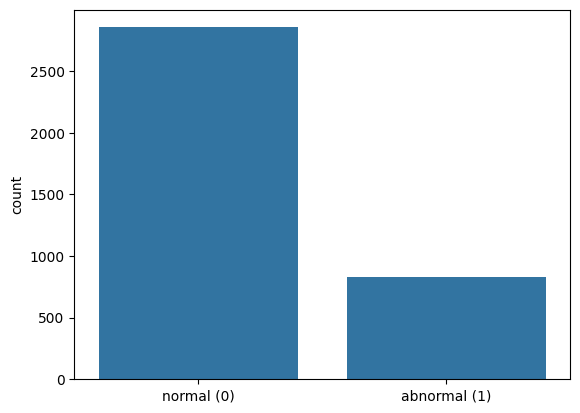

,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean,mfcc6_mean,mfcc7_mean,mfcc8_mean,mfcc9_mean,mfcc10_mean,...,mfcc4_std,mfcc5_std,mfcc6_std,mfcc7_std,mfcc8_std,mfcc9_std,mfcc10_std,mfcc11_std,mfcc12_std,mfcc13_std
0,-254.894684,20.302010,29.536432,22.771187,10.476133,12.026559,6.437137,4.289824,2.640546,5.904438,...,4.668721,4.105862,3.484509,2.995849,3.251541,3.373689,3.227825,3.025101,3.285295,2.767606
1,-264.525269,47.955196,31.116093,13.411427,6.604259,3.859557,1.145443,2.723909,0.902089,3.090525,...,6.344787,7.899178,6.719737,4.280223,3.589770,3.174209,3.024146,3.097579,2.866457,3.003225
2,-297.487000,36.259377,45.223820,14.961040,18.376766,7.381001,10.361653,0.739179,7.681967,1.390419,...,4.866203,7.645961,3.329160,4.869174,3.549373,3.531684,3.013973,2.806368,3.124293,2.958954
3,-280.577179,54.925072,30.691113,23.961609,6.546364,9.328610,2.989173,1.685358,3.512840,0.734703,...,6.438685,6.458922,5.211511,4.799251,5.480114,6.822571,5.312037,3.544802,4.099167,3.872746
4,-266.613495,57.948544,30.325579,22.595510,17.173113,12.237260,6.241416,4.622953,5.561380,5.021791,...,6.070164,7.609652,5.870015,4.180736,3.832866,3.392121,3.408708,3.172079,2.745392,2.679134


In [6]:
a = load_data(project_folder + "mfcc_features_tree_a.data")
b = load_data(project_folder + "mfcc_features_tree_b.data")

X = np.array(a)    # 1 row per wav, 26 columns
y = np.array(b)    # 0 = normal, 1 = abnormal

# the names of the 26 features: mfcc1_mean ... mfcc13_mean, then mfcc1_std ... mfcc13_std
feature_names = []
for i in range(1, N_MFCC + 1):
    feature_names.append("mfcc" + str(i) + "_mean")
for i in range(1, N_MFCC + 1):
    feature_names.append("mfcc" + str(i) + "_std")

print("dimension of our data:", X.shape)
print("normal (0):", np.sum(y == 0), "| abnormal (1):", np.sum(y == 1))

sns.countplot(x=y)    # like the course: how many wavs in each class
plt.xticks([0, 1], ["normal (0)", "abnormal (1)"])
plt.show()

pd.DataFrame(X, columns=feature_names).head()

In [7]:
# The formulas of the course, on our data (before the first question of the tree)
p_normal = np.mean(y == 0)
p_abnormal = np.mean(y == 1)

gini = 1 - p_normal ** 2 - p_abnormal ** 2                                    # Gini impurity
entropy = -(p_normal * np.log2(p_normal) + p_abnormal * np.log2(p_abnormal))  # entropy (ID3, Quinlan)

print("p(normal) = {:.3f} | p(abnormal) = {:.3f}".format(p_normal, p_abnormal))
print("Gini impurity = {:.3f}   (0 = only 1 class, 0.5 = 50/50)".format(gini))
print("Entropy       = {:.3f}   (0 = only 1 class, 1 = 50/50)".format(entropy))
# The tree looks for the question "feature <= threshold" (like "Weight < 167.5" in the course)
# that makes the 2 groups the most pure (the biggest gain), then again in each group, and so on

p(normal) = 0.776 | p(abnormal) = 0.224
Gini impurity = 0.348   (0 = only 1 class, 0.5 = 50/50)
Entropy       = 0.768   (0 = only 1 class, 1 = 50/50)


In [8]:
# 67% to train, 33% to test, stratified (the same % of abnormal in both parts)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y, random_state=66)
print("train:", X_train.shape[0], "wavs | test:", X_test.shape[0], "wavs")

train: 2466 wavs | test: 1215 wavs


Best tree: criterion = gini | max_depth = 10 | test F1 = 0.629 | test recall = 0.707


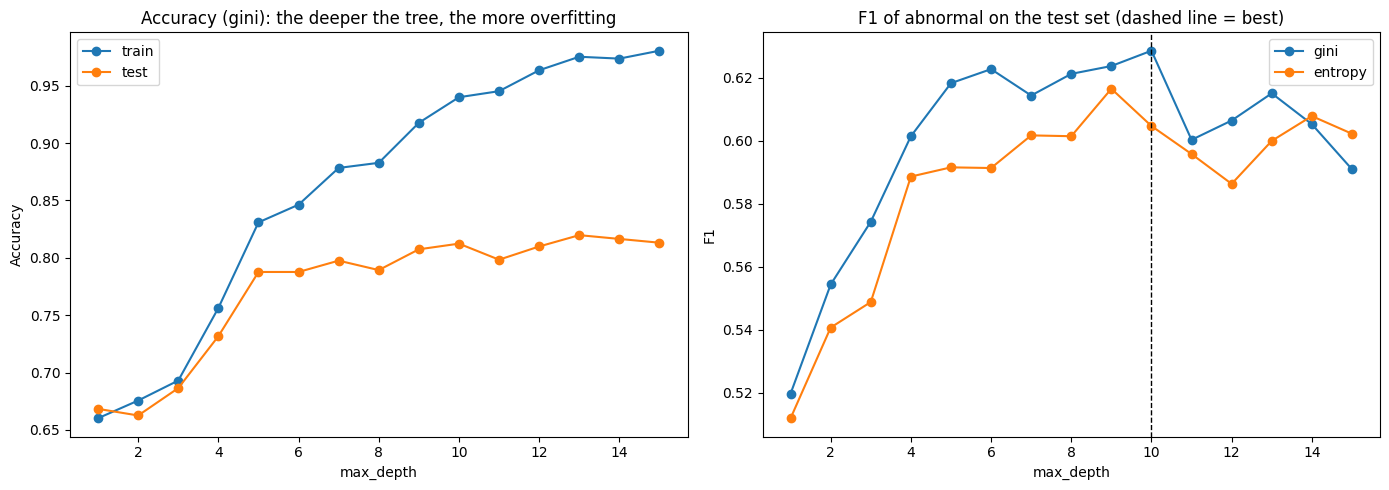

In [9]:
# 2. Which max_depth? And which criterion: "gini" (Gini impurity) or "entropy" (ID3)? Both are in the course.
#    We try max_depth = 1 to 15 with both, and look at the test set
rows = []
for criterion in ["gini", "entropy"]:
    for depth in range(1, 16):
        tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, class_weight="balanced", random_state=0)
        tree.fit(X_train, y_train)
        y_pred = tree.predict(X_test)
        rows.append({
            "criterion": criterion,
            "max_depth": depth,
            "train_accuracy": tree.score(X_train, y_train),
            "test_accuracy": accuracy_score(y_test, y_pred),
            "test_recall": recall_score(y_test, y_pred),    # recall and f1: of the abnormal class
            "test_f1": f1_score(y_test, y_pred),
        })
search = pd.DataFrame(rows)

# the best tree = the highest F1 of abnormal on the test set
# (F1 balances the recall = find the sick hearts, and the precision = not too many false alarms)
best = search.loc[search["test_f1"].idxmax()]
best_criterion = best["criterion"]
best_depth = int(best["max_depth"])
print("Best tree: criterion =", best_criterion, "| max_depth =", best_depth,
      "| test F1 = {:.3f} | test recall = {:.3f}".format(best["test_f1"], best["test_recall"]))

# ONE figure: left = the overfitting (train vs test accuracy), right = the F1 of abnormal (gini vs entropy)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
gini_rows = search[search["criterion"] == "gini"]
plt.plot(gini_rows["max_depth"], gini_rows["train_accuracy"], marker="o", label="train")
plt.plot(gini_rows["max_depth"], gini_rows["test_accuracy"], marker="o", label="test")
plt.title("Accuracy (gini): the deeper the tree, the more overfitting")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
for criterion in ["gini", "entropy"]:
    criterion_rows = search[search["criterion"] == criterion]
    plt.plot(criterion_rows["max_depth"], criterion_rows["test_f1"], marker="o", label=criterion)
plt.axvline(best_depth, color="black", linestyle="--", linewidth=1)    # the best max_depth
plt.title("F1 of abnormal on the test set (dashed line = best)")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.legend()

plt.tight_layout()
plt.savefig(plots_folder + "tp4_choose_depth.png")
plt.show()

In [10]:
# 3. The pruned tree , with the best settings
tree = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth, class_weight="balanced", random_state=0)
tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

y_true, y_pred = y_test, tree.predict(X_test)
print(classification_report(y_true, y_pred, target_names=["normal", "abnormal"]))

Accuracy on training set: 0.940
Accuracy on test set: 0.812
              precision    recall  f1-score   support

      normal       0.91      0.84      0.87       942
    abnormal       0.57      0.71      0.63       273

    accuracy                           0.81      1215
   macro avg       0.74      0.77      0.75      1215
weighted avg       0.83      0.81      0.82      1215



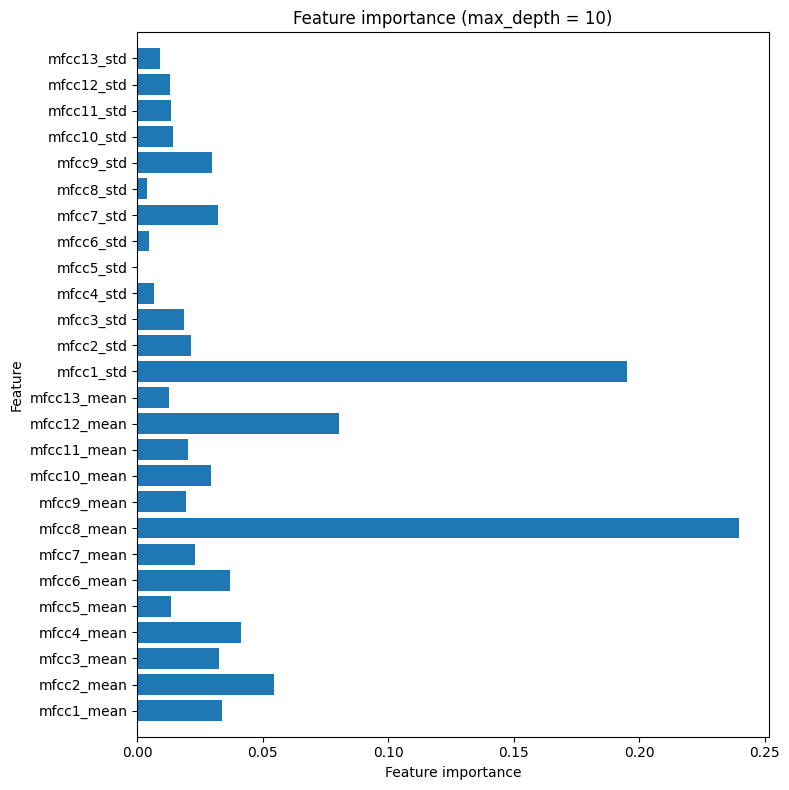

The 5 most important features:
mfcc8_mean     0.240
mfcc1_std      0.195
mfcc12_mean    0.081
mfcc2_mean     0.055
mfcc4_mean     0.041
dtype: float64
Features never used by the tree: 1 of 26


In [11]:
# 4. Feature importance : how much each feature helped the tree to decide
#    (a number between 0 and 1, the sum = 1, 0 = never used)
def plot_feature_importances(model):
    plt.figure(figsize=(8, 8))
    n_features = len(feature_names)
    plt.barh(range(n_features), model.feature_importances_, align="center")
    plt.yticks(np.arange(n_features), feature_names)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.ylim(-1, n_features)


plot_feature_importances(tree)
plt.title("Feature importance (max_depth = " + str(best_depth) + ")")
plt.tight_layout()
plt.savefig(plots_folder + "tp4_feature_importance.png")
plt.show()

importances = pd.Series(tree.feature_importances_, index=feature_names).sort_values(ascending=False)
print("The 5 most important features:")
print(importances.head(5).round(3))
print("Features never used by the tree:", np.sum(tree.feature_importances_ == 0), "of", len(feature_names))

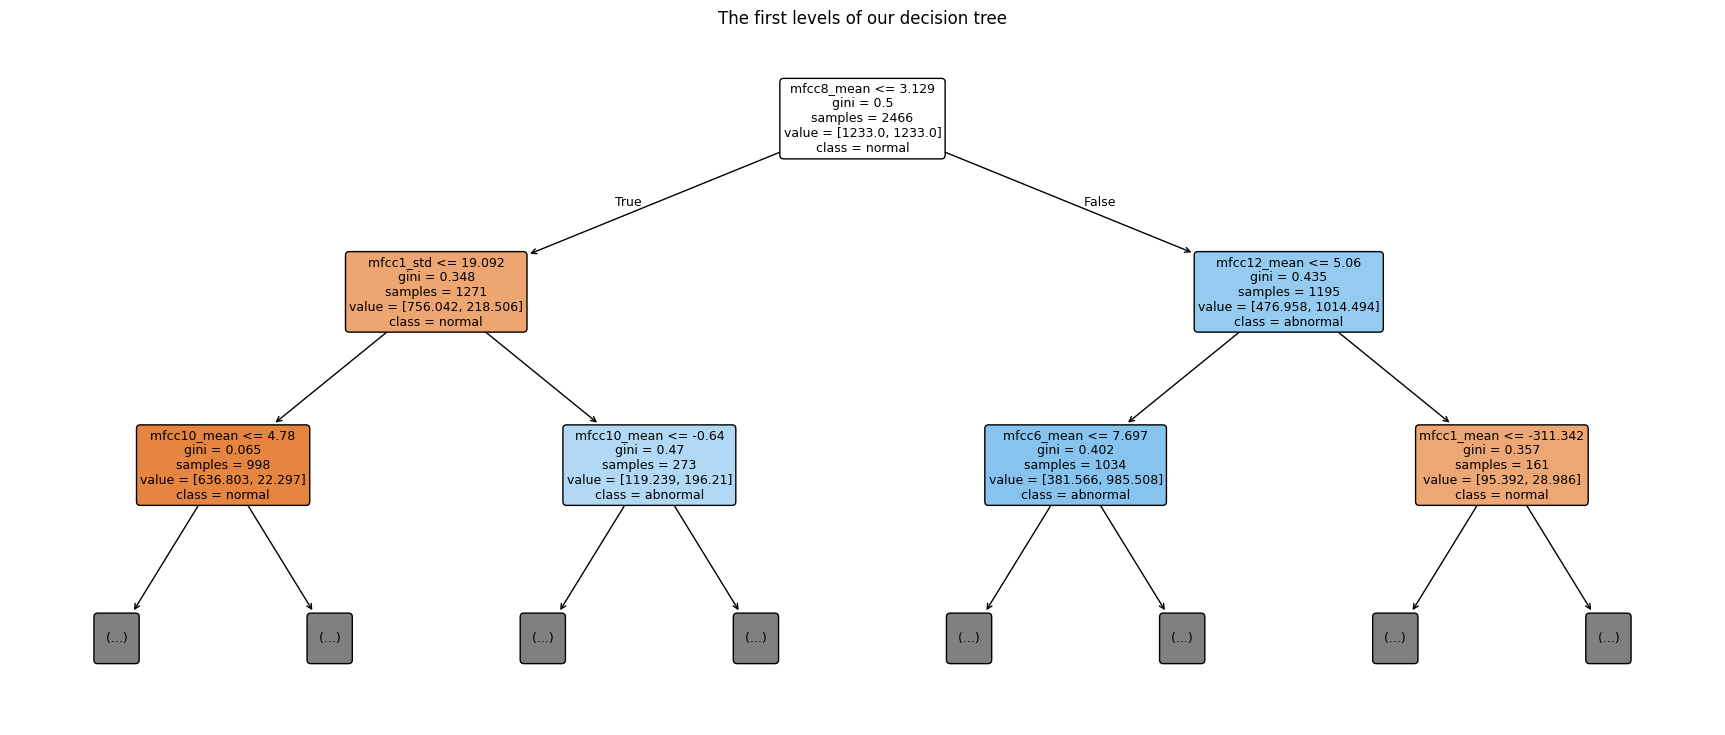

In [12]:
# 5. The tree itself (only the first 3 levels, the whole tree is too big to read)
# In each box: the gini (or entropy) of the box,
# samples = how many train wavs arrive in the box, value = [normal, abnormal] in the box (weighted),
# class = what the tree answers for them. True = the question is true -> go left.
# (with class_weight="balanced" the 2 classes weigh the same, so the first box is 50/50: gini = 0.5 or entropy = 1)
plt.figure(figsize=(22, 9))
plot_tree(tree, max_depth=2, feature_names=feature_names, class_names=["normal", "abnormal"],
          filled=True, rounded=True, fontsize=9)
plt.title("The first levels of our decision tree")
plt.savefig(plots_folder + "tp4_tree.png")
plt.show()

In [13]:
# 6. The 3 folds (like TP3): each fold, 1 third of the wavs = test (33%), the 2 other thirds = train (66%)
#    The same KFold as TP3 on the same wavs -> the same 3 folds as the SVM: fair comparison in MLflow
kfold = KFold(n_splits=3, shuffle=True, random_state=1)

results = []               # the metrics of each fold
confusion_matrices = []    # kept to draw them after
fold = 1
for train_index, test_index in kfold.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    tree = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth, class_weight="balanced", random_state=0)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_test)
    y_train_pred = tree.predict(X_train)    # also on its own train wavs: to compare training vs validation

    print("--- Fold", fold, ": train =", len(train_index), "wavs | test =", len(test_index), "wavs")
    print(classification_report(y_test, y_pred, target_names=["normal", "abnormal"]))

    results.append({
        "fold": fold,
        "accuracy": accuracy_score(y_test, y_pred),     # % of good answers
        "precision": precision_score(y_test, y_pred),   # these 3: for the abnormal class (1)
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "train_accuracy": accuracy_score(y_train, y_train_pred),    # the same 4 metrics on the train wavs
        "train_precision": precision_score(y_train, y_train_pred),
        "train_recall": recall_score(y_train, y_train_pred),
        "train_f1": f1_score(y_train, y_train_pred),
    })
    confusion_matrices.append(confusion_matrix(y_test, y_pred))
    fold = fold + 1

table = pd.DataFrame(results)
ipd.display(table.round(3))
print("Mean of the 3 folds:")
print(table[["accuracy", "precision", "recall", "f1"]].mean().round(3))

--- Fold 1 : train = 2454 wavs | test = 1227 wavs
              precision    recall  f1-score   support

      normal       0.92      0.84      0.88       937
    abnormal       0.60      0.76      0.67       290

    accuracy                           0.82      1227
   macro avg       0.76      0.80      0.77      1227
weighted avg       0.84      0.82      0.83      1227

--- Fold 2 : train = 2454 wavs | test = 1227 wavs
              precision    recall  f1-score   support

      normal       0.91      0.83      0.87       962
    abnormal       0.54      0.71      0.62       265

    accuracy                           0.81      1227
   macro avg       0.73      0.77      0.74      1227
weighted avg       0.83      0.81      0.82      1227



--- Fold 3 : train = 2454 wavs | test = 1227 wavs
              precision    recall  f1-score   support

      normal       0.90      0.84      0.87       956
    abnormal       0.54      0.68      0.60       271

    accuracy                           0.80      1227
   macro avg       0.72      0.76      0.73      1227
weighted avg       0.82      0.80      0.81      1227



,fold,accuracy,precision,recall,f1,train_accuracy,train_precision,train_recall,train_f1
0,1,0.822,0.596,0.762,0.669,0.932,0.772,0.974,0.861
1,2,0.808,0.543,0.713,0.617,0.910,0.720,0.993,0.834
2,3,0.801,0.540,0.679,0.601,0.950,0.821,0.995,0.900


Mean of the 3 folds:
accuracy     0.810
precision    0.559
recall       0.718
f1           0.629
dtype: float64


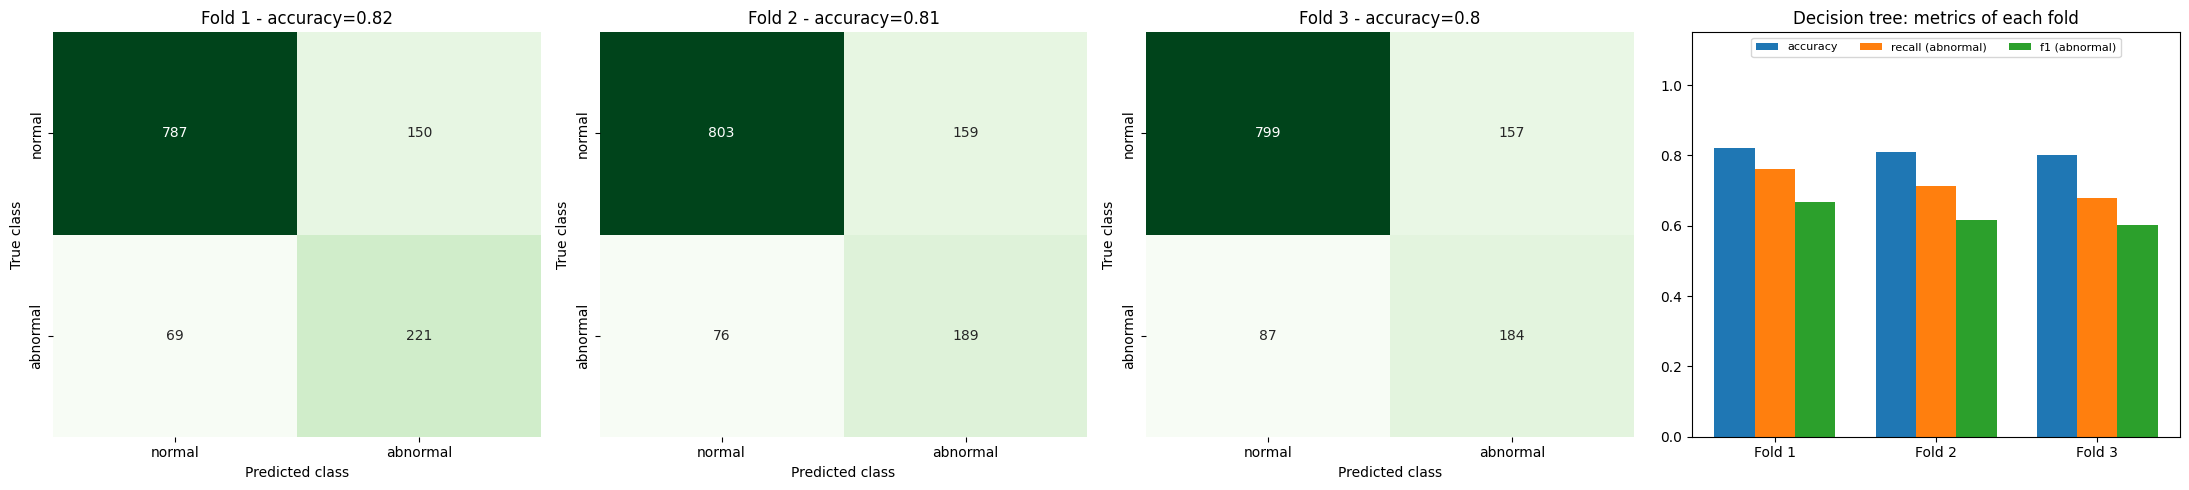

In [14]:
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of test wavs of class i (true) that the tree put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


# ONE figure: the confusion matrix of each fold + the metrics of each fold
plt.figure(figsize=(22, 5))
for i in range(3):
    plt.subplot(1, 4, i + 1)
    PlotConfusionMatrix(confusion_matrices[i],
                        "Fold " + str(i + 1) + " - accuracy=" + str(round(results[i]["accuracy"], 2)))

plt.subplot(1, 4, 4)
x = np.arange(3)    # 0, 1, 2 = fold 1, 2, 3
plt.bar(x - 0.25, table["accuracy"], width=0.25, label="accuracy")
plt.bar(x, table["recall"], width=0.25, label="recall (abnormal)")
plt.bar(x + 0.25, table["f1"], width=0.25, label="f1 (abnormal)")
plt.xticks(x, ["Fold 1", "Fold 2", "Fold 3"])
plt.ylim(0, 1.15)    # a bit of space above the bars for the legend
plt.title("Decision tree: metrics of each fold")
plt.legend(loc="upper center", ncol=3, fontsize=8)

plt.tight_layout()
plt.savefig(plots_folder + "tp4_tree_figure.png")
plt.show()

Fold 1 : training F1 = 0.861 | validation F1 = 0.669 (with all its train wavs)


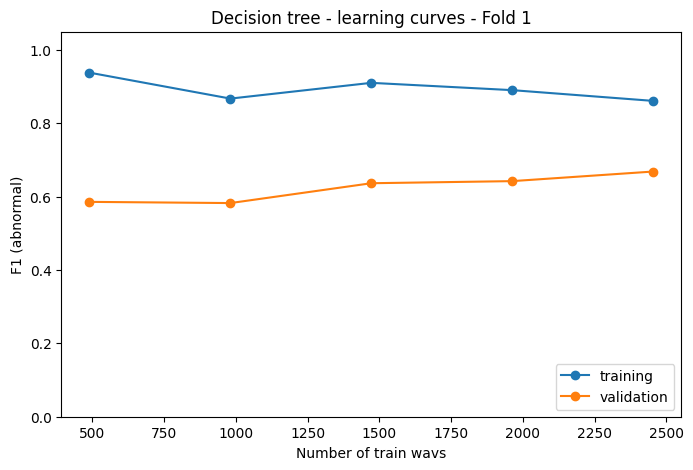

Fold 2 : training F1 = 0.834 | validation F1 = 0.617 (with all its train wavs)


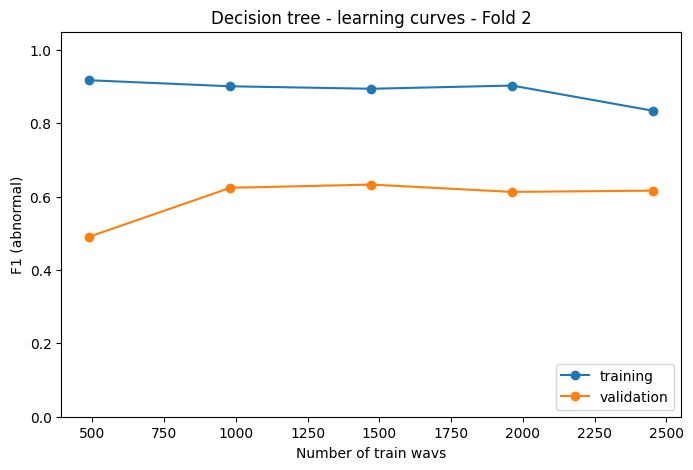

Fold 3 : training F1 = 0.900 | validation F1 = 0.601 (with all its train wavs)


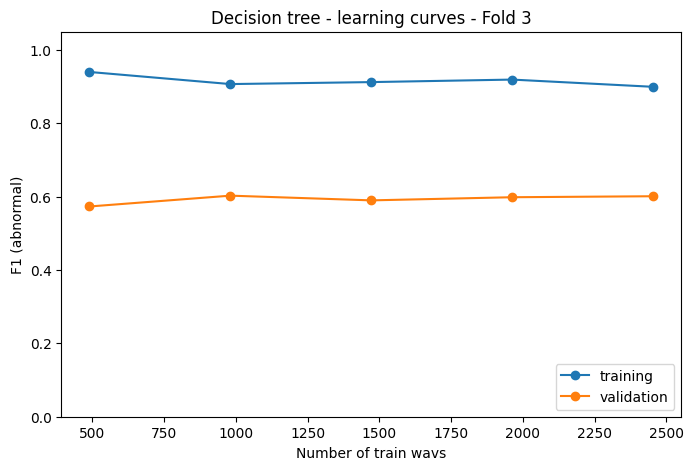

In [15]:
# 7. Training vs validation: the learning curves (the same 3 folds)
#    For each fold, the tree learns on 20%, 40%, 60%, 80% and 100% of its train wavs. Each time we look at its F1
#    (abnormal) on these train wavs (= training) and on the third of the wavs it never saw (= validation).
#    - a big gap between the 2 curves = overfitting (the tree learns its train wavs by heart)
#    - the validation curve still goes up at the end = more wavs would help
#    shuffle=True: our wavs are sorted (all the abnormal ones first), so they are mixed before taking the 20%, 40%, ...
model = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth, class_weight="balanced", random_state=0)
sizes, train_scores, val_scores = learning_curve(model, X, y, cv=kfold, scoring="f1",
                                                 train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
                                                 shuffle=True, random_state=0)
# train_scores and val_scores: 1 row per size, 1 column per fold

# 1 figure per fold: the learning curves of this fold alone
for fold in range(3):
    print("Fold", fold + 1, ": training F1 = {:.3f} | validation F1 = {:.3f} (with all its train wavs)".format(
        train_scores[-1, fold], val_scores[-1, fold]))
    plt.figure(figsize=(8, 5))
    plt.plot(sizes, train_scores[:, fold], "o-", color="tab:blue", label="training")
    plt.plot(sizes, val_scores[:, fold], "o-", color="tab:orange", label="validation")
    plt.title("Decision tree - learning curves - Fold " + str(fold + 1))
    plt.xlabel("Number of train wavs")
    plt.ylabel("F1 (abnormal)")
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right")
    plt.savefig(plots_folder + "tp4_tree_learning_curve_fold" + str(fold + 1) + ".png")
    plt.show()

With all the train wavs -> training F1 = 0.865 | validation F1 = 0.629 (mean of the 3 folds)


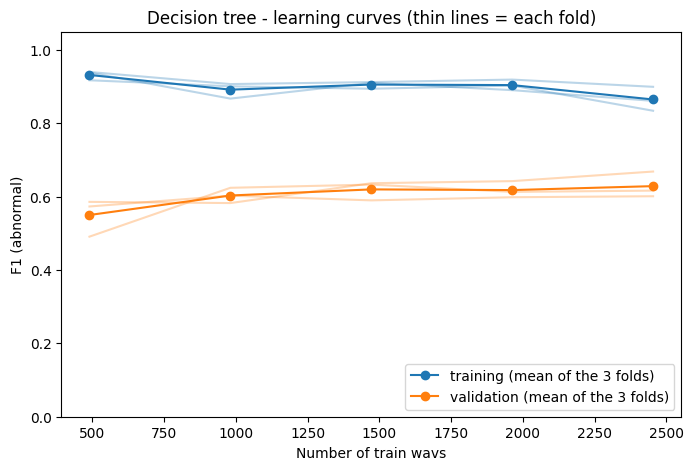

In [16]:
# The mean of the 3 folds: the same learning curves, thick lines = the mean (thin lines = each fold)
print("With all the train wavs -> training F1 = {:.3f} | validation F1 = {:.3f} (mean of the 3 folds)".format(
    train_scores[-1].mean(), val_scores[-1].mean()))

plt.figure(figsize=(8, 5))
for fold in range(3):    # thin lines: each fold
    plt.plot(sizes, train_scores[:, fold], color="tab:blue", alpha=0.3)
    plt.plot(sizes, val_scores[:, fold], color="tab:orange", alpha=0.3)
plt.plot(sizes, train_scores.mean(axis=1), "o-", color="tab:blue", label="training (mean of the 3 folds)")
plt.plot(sizes, val_scores.mean(axis=1), "o-", color="tab:orange", label="validation (mean of the 3 folds)")
plt.title("Decision tree - learning curves (thin lines = each fold)")
plt.xlabel("Number of train wavs")
plt.ylabel("F1 (abnormal)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.savefig(plots_folder + "tp4_tree_learning_curves.png")
plt.show()

In [17]:
# ==================== MLflow (Service 6): this model in its own run ====================
# the server and our experiment, again here: even if we run only this cell, the run goes to audio_benchmark (not "Default")
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark")

run_name = "decision_tree_" + best_criterion + "_depth" + str(best_depth)
with mlflow.start_run(run_name=run_name):
    # 1. params = the settings we chose
    mlflow.log_param("model", "DecisionTree")
    mlflow.log_param("criterion", best_criterion)
    mlflow.log_param("max_depth", best_depth)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("n_folds", 3)
    mlflow.log_param("features", "MFCC mean + std (26)")
    mlflow.log_param("seconds", SECONDS)
    mlflow.log_param("sample_rate", SR)
    mlflow.log_param("n_features", X.shape[1])
    mlflow.log_param("n_wavs", len(y))

    # 2. metrics = the mean of the 3 folds (the same names as the SVM runs, to compare them)
    for metric in ["accuracy", "precision", "recall", "f1"]:
        mlflow.log_metric("mean_" + metric, table[metric].mean())
    for r in results:    # the results of each fold, also here: fold1_accuracy, fold1_precision, ..., fold3_f1
        for metric in ["accuracy", "precision", "recall", "f1"]:
            mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])

    # 3. artifacts = the figures of this notebook
    mlflow.log_artifact(plots_folder + "tp4_choose_depth.png")
    mlflow.log_artifact(plots_folder + "tp4_feature_importance.png")
    mlflow.log_artifact(plots_folder + "tp4_tree.png")
    mlflow.log_artifact(plots_folder + "tp4_tree_figure.png")
    mlflow.log_artifact(plots_folder + "tp4_tree_learning_curves.png")    # training vs validation

    # 4. the model. The 3 folds were only to MEASURE the tree: the tree we keep is trained on ALL the wavs
    final_tree = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth,
                                        class_weight="balanced", random_state=0)
    final_tree.fit(X, y)
    mlflow.sklearn.log_model(final_tree, "model", input_example=X[:5])

    # 5. the 3 folds: 1 small run per fold INSIDE this run (nested=True), with its training and validation results
    for r in results:
        with mlflow.start_run(run_name=run_name + "_fold" + str(r["fold"]), nested=True):
            mlflow.log_param("fold", r["fold"])
            for metric in ["accuracy", "precision", "recall", "f1"]:
                mlflow.log_metric("train_" + metric, r["train_" + metric])    # on the 2/3 train wavs of the fold
                mlflow.log_metric("val_" + metric, r[metric])                 # on the 1/3 validation wavs (never seen)
            mlflow.log_artifact(plots_folder + "tp4_tree_learning_curve_fold" + str(r["fold"]) + ".png")    # its learning curves

🏃 View run decision_tree_gini_depth10_fold1 at: http://localhost:5000/#/experiments/1/runs/d2ca003a74ae47e98c02a9c59f4ba0d5
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run decision_tree_gini_depth10_fold2 at: http://localhost:5000/#/experiments/1/runs/8f497597c73e420c971494735d733b82
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run decision_tree_gini_depth10_fold3 at: http://localhost:5000/#/experiments/1/runs/16666050e1ab4cd7a156700ba94d3380
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run decision_tree_gini_depth10 at: http://localhost:5000/#/experiments/1/runs/c07a9e71ed3b4230977b362743c6c928
🧪 View experiment at: http://localhost:5000/#/experiments/1


In [18]:
# All the runs of the experiment (the SVM runs of TP3 + this tree), the highest recall first:
# the project keeps the model with the highest recall of abnormal (the sick hearts)
runs = mlflow.search_runs(experiment_names=["audio_benchmark"])
runs = runs[runs["metrics.mean_recall"].notna()]    # only the main runs (the fold runs inside them have no mean_recall)
columns = ["tags.mlflow.runName", "params.model", "params.features", "metrics.mean_recall",
           "metrics.mean_f1", "metrics.mean_precision", "metrics.mean_accuracy"]
ipd.display(runs[columns].sort_values("metrics.mean_recall", ascending=False).round(3))

,tags.mlflow.runName,params.model,params.features,metrics.mean_recall,metrics.mean_f1,metrics.mean_precision,metrics.mean_accuracy
8,cnn,CNN,"mel spectrogram 40 x 157 (5 s, 2000 Hz)",0.925,0.655,0.510,0.778
36,svm_rbf_2s,SVM,mel spectrogram flatten (30 bands),0.836,0.638,0.516,0.787
25,svm_rbf_5s,SVM,mel spectrogram flatten (30 bands),0.829,0.639,0.521,0.791
20,vgg16,VGG16,mel spectrogram 40 x 157 -> magma image 224 x ...,0.810,0.708,0.629,0.850
13,svm_rbf_10s,SVM,mel spectrogram flatten (30 bands),0.809,0.639,0.528,0.795
32,resnet50,ResNet50,mel spectrogram 40 x 157 -> magma image 224 x ...,0.800,0.763,0.730,0.889
4,decision_tree_gini_depth10,DecisionTree,MFCC mean + std (26),0.718,0.629,0.559,0.810
44,decision_tree_gini_depth10,DecisionTree,MFCC mean + std (26),0.718,0.629,0.559,0.810
40,svm_linear_2s,SVM,mel spectrogram flatten (30 bands),0.616,0.484,0.399,0.706
19,svm_linear_10s,SVM,mel spectrogram flatten (30 bands),0.460,0.454,0.448,0.751
